# 01 — CNN Baseline (Channel 1)

**Goal:** Use one Channel 1 satellite image to predict the cyclone's target wind speed six hours later.

- Labels: `/content/data/samples_6h`
- Satellite patches: `/content/data/patches_full`
- Satellite patches contain two 64 × 64 channels stored as `float16`; this experiment uses Channel 1 only.
- `TARGET_WIND` is the six-hour-ahead target associated with the label timestamp.
- Train/validation/test split names are `1_train`, `2_val`, and `3_test`.

**Fair-comparison rule:** The CNN uses one image at a timestamp, while ConvLSTM uses four images ending at that same timestamp. Both use the same target column and split definitions.

## 1. Connect Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Extract the dataset archive

In [ ]:
import os
import tarfile

archive = "/content/drive/MyDrive/CycloneConnect/dataset_from_BDA/cyclone_data.tar.gz"
data_root = "/content/data"

required_dirs = [
    os.path.join(data_root, "samples_6h"),
    os.path.join(data_root, "patches_full"),
]

if all(os.path.exists(path) for path in required_dirs):
    print("Dataset folders already exist. Skipping extraction.")
else:
    if not os.path.exists(archive):
        raise FileNotFoundError(
            f"Archive not found: {archive}\n"
            "Check that cyclone_data.tar.gz is inside MyDrive/cyclone."
        )
    os.makedirs(data_root, exist_ok=True)
    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall(data_root)
    print("Dataset extraction finished.")

for path in required_dirs:
    print(path, "exists:", os.path.exists(path))

/tmp/ipykernel_9644/2225346194.py:22: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(data_root)


Dataset extraction finished.
/content/data/samples_6h exists: True
/content/data/patches_full exists: True


## 3. Load labels and satellite patches

In [ ]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

labels_path = "/content/data/samples_6h"
patches_path = "/content/data/patches_full"

label_files = glob.glob(os.path.join(labels_path, "*.parquet"))
patch_files = glob.glob(os.path.join(patches_path, "*.parquet"))

print("Label parquet files:", len(label_files))
print("Patch parquet files:", len(patch_files))

if not label_files or not patch_files:
    raise FileNotFoundError(
        "Could not find parquet files. Check the extracted folder structure."
    )

L = pd.read_parquet(labels_path)
P = pd.read_parquet(patches_path)

L["ISO_TIME"] = pd.to_datetime(L["ISO_TIME"], errors="coerce")
P["T"] = pd.to_datetime(P["T"], errors="coerce")

print("Labels shape:", L.shape)
print("Patches shape:", P.shape)
print("Label columns:", L.columns.tolist())
print("Patch columns:", P.columns.tolist())
print("\nLabel split counts:")
print(L["SPLIT"].value_counts(dropna=False))

Label parquet files: 1
Patch parquet files: 1155
Labels shape: (4295, 8)
Patches shape: (10814, 5)
Label columns: ['SID', 'BASIN', 'ISO_TIME', 'LAT', 'LON', 'WIND_KT', 'TARGET_WIND', 'SPLIT']
Patch columns: ['SID', 'T', 'LAT', 'LON', 'PATCH']

Label split counts:
SPLIT
1_train    2806
3_test     1013
2_val       476
Name: count, dtype: int64


## 4. Assign the existing cyclone splits to patches

In [ ]:
# The existing project assigns each cyclone to a single split.
cyclone_splits = L[["SID", "SPLIT"]].drop_duplicates()

multi_split_cyclones = (
    cyclone_splits.groupby("SID")["SPLIT"].nunique().gt(1).sum()
)
print("Cyclones appearing in multiple splits:", int(multi_split_cyclones))

if multi_split_cyclones:
    raise ValueError(
        "At least one cyclone appears in multiple splits. "
        "Resolve the split assignment before training to avoid leakage."
    )

P_split = P.merge(
    cyclone_splits,
    on="SID",
    how="left",
    validate="many_to_one"
)

P_split = P_split[
    P_split["SPLIT"].isin(["1_train", "2_val", "3_test"])
].copy()

print("Patch counts by split:")
print(P_split["SPLIT"].value_counts())

Cyclones appearing in multiple splits: 0
Patch counts by split:
SPLIT
1_train    7174
3_test     2691
2_val       949
Name: count, dtype: int64


## 5. Decode Channel 1 and match each image to its target

In [ ]:
# Each patch stores two 64x64 channels as float16 bytes.
# Channel 1 is values[0], matching the existing ConvLSTM notebook.

image_records = []
skipped_all_missing = 0

for row in P_split.itertuples(index=False):
    values = np.frombuffer(row.PATCH, dtype=np.float16)

    if values.size != 2 * 64 * 64:
        continue

    patch = values.reshape(2, 64, 64)
    channel1 = patch[0].astype(np.float32)

    # Exclude an image if every Channel 1 pixel is missing.
    if not np.isfinite(channel1).any():
        skipped_all_missing += 1
        continue

    image_records.append({
        "SID": row.SID,
        "T": row.T,
        "SPLIT": row.SPLIT,
        "IMAGE": channel1
    })

images_df = pd.DataFrame(image_records)

print("Patches assigned to a split:", len(P_split))
print("Usable Channel 1 images:", len(images_df))
print("Completely missing Channel 1 images skipped:", skipped_all_missing)

# Match image timestamp to the same timestamp in labels.
# TARGET_WIND is the future (six-hour-ahead) wind-speed target.
label_targets = L[["SID", "ISO_TIME", "TARGET_WIND"]].copy()
label_targets = label_targets.dropna(subset=["SID", "ISO_TIME", "TARGET_WIND"])

duplicate_keys = label_targets.duplicated(["SID", "ISO_TIME"]).sum()
print("Duplicate non-missing label keys:", int(duplicate_keys))

if duplicate_keys:
    raise ValueError(
        "Duplicate (SID, ISO_TIME) target rows found. "
        "Inspect the label data before continuing."
    )

dataset_df = images_df.merge(
    label_targets,
    left_on=["SID", "T"],
    right_on=["SID", "ISO_TIME"],
    how="inner",
    validate="many_to_one"
)

dataset_df = dataset_df.dropna(subset=["TARGET_WIND"]).copy()
dataset_df["TARGET_WIND"] = dataset_df["TARGET_WIND"].astype(np.float32)

print("\nMatched images with targets:", len(dataset_df))
print("Matched samples by split:")
print(dataset_df["SPLIT"].value_counts())
print("\nTarget wind speed (knots):")
print(dataset_df["TARGET_WIND"].describe())

Patches assigned to a split: 10814
Usable Channel 1 images: 10811
Completely missing Channel 1 images skipped: 3
Duplicate non-missing label keys: 0

Matched images with targets: 4290
Matched samples by split:
SPLIT
1_train    2801
3_test     1013
2_val       476
Name: count, dtype: int64

Target wind speed (knots):
count    4290.000000
mean       48.835663
std        24.553194
min        15.000000
25%        30.000000
50%        40.000000
75%        60.000000
max       165.000000
Name: TARGET_WIND, dtype: float64


## 6. Prepare train, validation, and test arrays

In [ ]:
# Calculate normalization statistics from finite pixels in TRAIN images only.
train_rows = dataset_df[dataset_df["SPLIT"] == "1_train"]

if train_rows.empty:
    raise ValueError("No training images matched with target wind speeds.")

train_pixel_sum = 0.0
train_pixel_squared_sum = 0.0
train_pixel_count = 0

for image in train_rows["IMAGE"]:
    valid = image[np.isfinite(image)].astype(np.float64)
    train_pixel_sum += valid.sum()
    train_pixel_squared_sum += np.square(valid).sum()
    train_pixel_count += valid.size

if train_pixel_count == 0:
    raise ValueError("No valid pixels were found in the training images.")

pixel_mean = train_pixel_sum / train_pixel_count
pixel_variance = max(
    train_pixel_squared_sum / train_pixel_count - pixel_mean**2, 0.0
)
pixel_std = float(np.sqrt(pixel_variance))

if not np.isfinite(pixel_std) or pixel_std == 0:
    raise ValueError(f"Invalid training pixel standard deviation: {pixel_std}")

print("Training pixel mean:", pixel_mean)
print("Training pixel standard deviation:", pixel_std)

def prepare_image(image):
    # Replace missing pixels with the TRAINING pixel mean.
    # After standardization these pixels become zero.
    image = image.astype(np.float32).copy()
    image[~np.isfinite(image)] = pixel_mean
    image = (image - pixel_mean) / pixel_std
    return image[..., np.newaxis]  # (64, 64, 1)

arrays = {}

for split_name, short_name in [
    ("1_train", "train"),
    ("2_val", "val"),
    ("3_test", "test"),
]:
    part = dataset_df[dataset_df["SPLIT"] == split_name]

    if part.empty:
        raise ValueError(f"No matched samples found for split {split_name}.")

    X = np.stack([prepare_image(img) for img in part["IMAGE"]]).astype(np.float32)
    y = part["TARGET_WIND"].to_numpy(dtype=np.float32)

    arrays[f"X_{short_name}"] = X
    arrays[f"y_{short_name}"] = y

    print(f"{short_name}: X={X.shape}, y={y.shape}")

X_train, y_train = arrays["X_train"], arrays["y_train"]
X_val, y_val = arrays["X_val"], arrays["y_val"]
X_test, y_test = arrays["X_test"], arrays["y_test"]

print("\nMissing/non-finite values after preparation:")
print("Train:", int((~np.isfinite(X_train)).sum()))
print("Validation:", int((~np.isfinite(X_val)).sum()))
print("Test:", int((~np.isfinite(X_test)).sum()))

Training pixel mean: 239.26144846078967
Training pixel standard deviation: 31.93635833397661
train: X=(2801, 64, 64, 1), y=(2801,)
val: X=(476, 64, 64, 1), y=(476,)
test: X=(1013, 64, 64, 1), y=(1013,)

Missing/non-finite values after preparation:
Train: 0
Validation: 0
Test: 0


## 7. Preview a prepared image

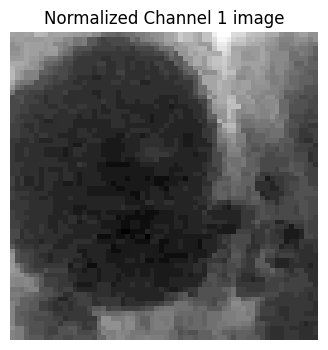

Example target wind speed (knots): 30.0


In [ ]:
plt.figure(figsize=(4, 4))
plt.imshow(X_train[0, :, :, 0], cmap="gray")
plt.title("Normalized Channel 1 image")
plt.axis("off")
plt.show()

print("Example target wind speed (knots):", float(y_train[0]))

## 8. Build the CNN baseline

In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, BatchNormalization,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)

cnn_model = Sequential([
    Input(shape=(64, 64, 1)),

    Conv2D(16, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(32, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),

    GlobalAveragePooling2D(),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="linear")
])

cnn_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,857 (101.00 KB)

 Trainable params: 25,633 (100.13 KB)

 Non-trainable params: 224 (896.00 B)

## 9. Train the CNN

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

history = cnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 176ms/step - loss: 2257.6709 - mean_absolute_error: 40.8295 - val_loss: 2933.2688 - val_mean_absolute_error: 48.2530 - learning_rate: 0.0010
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 170ms/step - loss: 1138.5513 - mean_absolute_error: 26.3909 - val_loss: 757.8044 - val_mean_absolute_error: 23.0810 - learning_rate: 0.0010
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 17s 195ms/step - loss: 648.9102 - mean_absolute_error: 19.4898 - val_loss: 723.0491 - val_mean_absolute_error: 22.0901 - learning_rate: 0.0010
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 18s 171ms/step - loss: 503.7075 - mean_absolute_error: 17.1750 - val_loss: 665.1169 - val_mean_absolute_error: 21.1513 - learning_rate: 0.0010
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 21s 172ms/step - loss: 438.4737 - mean_absolute_error: 15.9612 - val_loss: 530.0912 - val_mean_absolute_error: 19.5700 - learning_rate: 0.0010
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 172ms/step - loss: 424.4270 - mean_absolute_error:

## 10. Plot training history

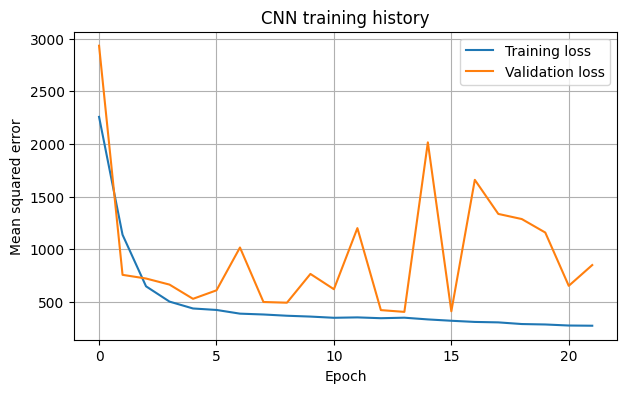

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("CNN training history")
plt.legend()
plt.grid(True)
plt.show()

## 11. Evaluate on the test set

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

test_predictions = cnn_model.predict(X_test, verbose=0).reshape(-1)

test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = float(np.sqrt(mean_squared_error(y_test, test_predictions)))

print("=== CNN CHANNEL 1 TEST RESULTS ===")
print(f"Test MAE:  {test_mae:.4f} knots")
print(f"Test RMSE: {test_rmse:.4f} knots")

=== CNN CHANNEL 1 TEST RESULTS ===
Test MAE:  12.8231 knots
Test RMSE: 17.6671 knots


## 12. Save model and results to Google Drive

In [ ]:
import json

output_dir = "/content/drive/MyDrive/CycloneConnect/DLG_docs/cyclone/model_results"
os.makedirs(output_dir, exist_ok=True)

model_path = os.path.join(output_dir, "cnn_channel1_model.keras")
metrics_path = os.path.join(output_dir, "cnn_channel1_metrics.json")
predictions_path = os.path.join(output_dir, "cnn_channel1_test_predictions.csv")

cnn_model.save(model_path)

metrics = {
    "model": "CNN",
    "channel": 1,
    "input": "single 64x64 satellite image",
    "target": "TARGET_WIND (six-hour-ahead wind speed, knots)",
    "test_samples": int(len(y_test)),
    "test_mae_knots": float(test_mae),
    "test_rmse_knots": float(test_rmse),
    "normalization_train_pixel_mean": float(pixel_mean),
    "normalization_train_pixel_std": float(pixel_std)
}

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

predictions_df = dataset_df[dataset_df["SPLIT"] == "3_test"][
    ["SID", "T", "TARGET_WIND"]
].copy().reset_index(drop=True)
predictions_df = predictions_df.rename(columns={"TARGET_WIND": "actual_wind_knots"})
predictions_df["predicted_wind_knots"] = test_predictions
predictions_df.to_csv(predictions_path, index=False)

print("Saved model:", model_path)
print("Saved metrics:", metrics_path)
print("Saved test predictions:", predictions_path)
print("\nMetrics:")
print(json.dumps(metrics, indent=2))

Saved model: /content/drive/MyDrive/CycloneConnect/DLG_docs/cyclone/model_results/cnn_channel1_model.keras
Saved metrics: /content/drive/MyDrive/CycloneConnect/DLG_docs/cyclone/model_results/cnn_channel1_metrics.json
Saved test predictions: /content/drive/MyDrive/CycloneConnect/DLG_docs/cyclone/model_results/cnn_channel1_test_predictions.csv

Metrics:
{
  "model": "CNN",
  "channel": 1,
  "input": "single 64x64 satellite image",
  "target": "TARGET_WIND (six-hour-ahead wind speed, knots)",
  "test_samples": 1013,
  "test_mae_knots": 12.823071479797363,
  "test_rmse_knots": 17.667119338276137,
  "normalization_train_pixel_mean": 239.26144846078967,
  "normalization_train_pixel_std": 31.93635833397661
}


Saved artifact at '/tmp/tmp0xyeobpz'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139916517719120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139916517717392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139916517719888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139916517719312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139916517719696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139916517719504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139916511412688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139916511413648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139916511413456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139916511413264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139916517718928:

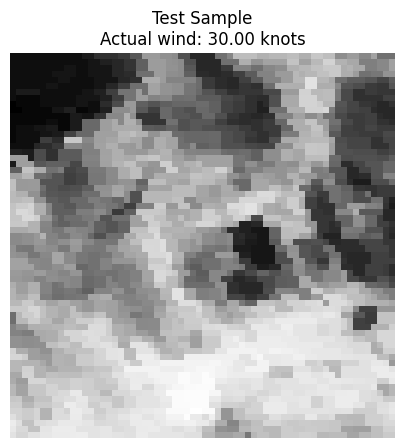


========== EXPORT COMPLETE ==========
Actual wind speed: 30.0 knots
CNN predicted wind: 20.333154678344727 knots
Prediction error: 9.666845 knots
Export folder: /content/cyclone_mobile_export

ZIP FILE CREATED: /content/cyclone_mobile_export.zip


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
# ==========================================
# EXPORT CNN MODEL + DEMONSTRATION TEST SAMPLE
# ==========================================

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Create export folder
export_dir = "/content/cyclone_mobile_export"
os.makedirs(export_dir, exist_ok=True)

# ------------------------------------------
# 1. EXPORT THE CNN MODEL TO TFLITE
# ------------------------------------------

converter = tf.lite.TFLiteConverter.from_keras_model(cnn_model)
tflite_model = converter.convert()

tflite_path = os.path.join(export_dir, "cyclone_cnn.tflite")

with open(tflite_path, "wb") as f:
    f.write(tflite_model)

print("TFLite model exported.")

# ------------------------------------------
# 2. EXPORT PREPROCESSING STATISTICS
# ------------------------------------------

preprocessing = {
    "pixel_mean": float(pixel_mean),
    "pixel_std": float(pixel_std),
    "image_height": 64,
    "image_width": 64,
    "channels": 1
}

with open(
    os.path.join(export_dir, "preprocessing.json"),
    "w"
) as f:
    json.dump(preprocessing, f, indent=4)

print("Preprocessing values exported.")

# ------------------------------------------
# 3. SELECT ONE REAL TEST IMAGE
# ------------------------------------------

test_samples = dataset_df[
    dataset_df["SPLIT"] == "3_test"
].reset_index(drop=True)

sample = test_samples.iloc[0]

raw_image = sample["IMAGE"].astype(np.float32)
actual_wind = float(sample["TARGET_WIND"])

# ------------------------------------------
# 4. EXPORT RAW IMAGE VALUES
# ------------------------------------------

np.savetxt(
    os.path.join(export_dir, "sample_channel1.csv"),
    raw_image,
    delimiter=",",
    fmt="%.6f"
)

print("Raw sample exported.")

# ------------------------------------------
# 5. EXPORT IMAGE PREVIEW
# ------------------------------------------

plt.figure(figsize=(5, 5))

plt.imshow(raw_image, cmap="gray")

plt.title(
    f"Test Sample\nActual wind: {actual_wind:.2f} knots"
)

plt.axis("off")

plt.savefig(
    os.path.join(export_dir, "sample_satellite.png"),
    bbox_inches="tight",
    dpi=150
)

plt.show()

# ------------------------------------------
# 6. EXPORT SAMPLE INFORMATION
# ------------------------------------------

sample_info = {
    "SID": str(sample["SID"]),
    "timestamp": str(sample["T"]),
    "actual_wind_knots": actual_wind
}

with open(
    os.path.join(export_dir, "sample_info.json"),
    "w"
) as f:
    json.dump(sample_info, f, indent=4)

# ------------------------------------------
# 7. TEST TFLITE PREDICTION
# ------------------------------------------

prepared_sample = prepare_image(raw_image)

interpreter = tf.lite.Interpreter(
    model_path=tflite_path
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

interpreter.set_tensor(
    input_details[0]["index"],
    prepared_sample[np.newaxis, ...].astype(np.float32)
)

interpreter.invoke()

prediction = interpreter.get_tensor(
    output_details[0]["index"]
)[0][0]

print("\n========== EXPORT COMPLETE ==========")
print("Actual wind speed:", actual_wind, "knots")
print("CNN predicted wind:", float(prediction), "knots")
print("Prediction error:", abs(actual_wind - prediction), "knots")
print("Export folder:", export_dir)

# ------------------------------------------
# 8. ZIP THE EXPORTED FILES
# ------------------------------------------

import shutil

zip_path = shutil.make_archive(
    "/content/cyclone_mobile_export",
    "zip",
    export_dir
)

print("\nZIP FILE CREATED:", zip_path)

In [ ]:
from google.colab import files

files.download("/content/cyclone_mobile_export.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>